# Will the Fed raise or cut rates?
#### Fine-tune a model on what they say. Mortgage and car-loan rates can move with it.


The Federal Open Market Committee (FOMC) is the Fed group that sets the federal funds rate, the overnight rate banks charge each other. That is not your mortgage or car-loan APR. Markets still read the minutes, press conferences, and speeches for whether the Fed is leaning **raise / cut / hold**. That lean can move longer-term rates, which is often how mortgages, car loans, and credit cards reprice, but not one-for-one. When the committee sounds **hawkish**, they are leaning toward tighter policy (higher rates to cool inflation). When they sound **dovish**, they are leaning toward easier policy (lower rates to support growth).

[Shah et al. (2023)](https://aclanthology.org/2023.acl-long.368/) turn that reading into a three-way label on FOMC sentences (hawkish / dovish / neutral). We follow their Combined-S recipe and compare their RoBERTa models with [`nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16`](https://huggingface.co/nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16), an LLM, across full fine-tuning, LoRA, and QLoRA. All 33 runs (three models, no fine-tuning plus three methods, three seeds each) ran on one laptop GPU: a Dell Pro Max 16 Plus with an NVIDIA RTX PRO 5000 Blackwell (24 GB), as one Flyte 2 pipeline.

- Why Fed language can show up in mortgage and car-loan rates
- Full fine-tuning vs LoRA vs QLoRA, and where training memory goes
- RoBERTa-base / large and Nemotron 3 Nano 4B on the same Combined-S labels, 3-seed F1 vs the paper's Table 5
- One Flyte pipeline for every run, then serving the fine-tuned model with vLLM

The talk slides are in [`slides/`](slides/presentation_peft_talk.pdf).

**What this notebook runs.** It walks through the results of all 33 runs, and it trains one model live: a short RoBERTa-base + LoRA fine-tune in Step 2 (5 epochs, about 1.5 minutes on our laptop GPU). The 33 runs themselves were trained with `train_run.py`, `run_grid.py`, and the Flyte pipeline in `workflow.py` (commands in **CLI** at the end); their results are bundled with the repo, so the results table and chart work without retraining. Step 4 classifies new sentences with Nemotron LoRA if you have that checkpoint, and with your Step 2 model otherwise.

**What machine you need.**

| To run | Machine |
|---|---|
| This notebook, including the Step 2 fine-tune | An NVIDIA GPU with 4 GB or more (the run peaks at 2.2 GB), or an Apple Silicon Mac (MPS). A CPU works but is much slower. |
| RoBERTa-base / large, full and LoRA | NVIDIA GPU or Apple Silicon Mac. RoBERTa-large full fine-tuning peaks at 11.8 GB. |
| Any QLoRA run | An NVIDIA GPU with CUDA ([bitsandbytes](https://github.com/bitsandbytes-foundation/bitsandbytes) 4-bit does not run on Mac). |
| Nemotron 3 Nano 4B LoRA / QLoRA | An NVIDIA GPU with CUDA and about 10 GB free (LoRA peaks at 9.0 GB, QLoRA at 5.4 GB), plus the fused Mamba kernels (`bash run_fomc.sh nemotron-lora`). |
| All 33 runs as we did them | One Dell Pro Max 16 Plus laptop: NVIDIA RTX PRO 5000 Blackwell laptop GPU (24 GB), Intel Core Ultra 9 285HX, 128 GB RAM, WSL2. |


## One pipeline

![Talk slide: Flyte, 33 runs as one pipeline](images/slides/slide30_flyte.png)

*Slide 30 of the talk. The screenshot is the compare stage's report in the Flyte UI.*

A training script is enough to fine-tune RoBERTa **once**. It is the wrong shape for a **grid**: two encoder sizes and a 4B LLM, no fine-tuning plus three methods, three seeds each, with CPU data prep feeding GPU training. **Flyte 2 is one `workflow.py`.** Change the command, not the pipeline.

- **One DAG**: CPU `prepare_data`, GPU `train_one` / `grid`. Adding `nemotron-nano-4b` is another `--model_key`, the same way you add `roberta-large`.
- **Cheap reruns**: data prep is cached, a finished `metrics.json` is skipped, and a failed GPU task retries from its last epoch instead of restarting the grid.
- **Every stage explains itself**: each task writes a report (label mix, live training curve, the comparison table, the release gate).
- **Same code everywhere**: `flyte run --local` in this process, a local Flyte devbox for the UI, or a Flyte cluster.

Commands are in **CLI** at the end.


## Task
![Talk slide: worked example, hawkish or dovish](images/slides/slide27_worked_example.png)

*Slide 27 of the talk. Task and data: [Shah et al. (2023)](https://aclanthology.org/2023.acl-long.368/).*


[Shah et al. (2023)](https://aclanthology.org/2023.acl-long.368/) label FOMC minutes, pressers, and speeches as dovish / hawkish / neutral. Combined-S is ~2,480 sentences (1996–2022), seeds `5768`, `78516`, `944601`, random 80/20, not a year cutoff. Table 5 weighted F1: RoBERTa-base **0.698 ± 0.010**, RoBERTa-large **0.711 ± 0.011**. Data: [gtfintechlab/fomc-hawkish-dovish](https://github.com/gtfintechlab/fomc-hawkish-dovish) (CC BY-NC 4.0). Released model: [`gtfintechlab/FOMC-RoBERTa`](https://huggingface.co/gtfintechlab/FOMC-RoBERTa).

Their loop: AdamW, max length 256, 20% val, patience 7, last checkpoint. Combined-S winners: base batch 8 / 1e-5, large batch 16 / 1e-5. We keep that loop; LoRA / QLoRA only change adapters.


## Full fine-tuning vs LoRA vs QLoRA
![Talk slide: LoRA shrinks the training cost, not the base weights](images/slides/slide15_full_lora_qlora.png)

*Slide 15 of the talk. Diagram: [Dettmers et al., 2023](https://arxiv.org/abs/2305.14314).*


**Full fine-tuning** updates every weight, the setup in Shah et al. (2023), and our quality target.

**LoRA** ([Hu et al., 2021](https://arxiv.org/abs/2106.09685)) freezes \(W\) and trains \(B \times A\), scaled by \(\alpha / r\). On RoBERTa we target `query`, `key`, `value`, `dense` and fully train the head (`modules_to_save=["classifier"]`). On Nemotron we use r = 64 on the attention, MLP, and Mamba `in_proj` projections.

**QLoRA** ([Dettmers et al., 2023](https://arxiv.org/abs/2305.14314)) keeps those adapters and stores the frozen base in 4-bit (NF4) via [bitsandbytes](https://github.com/bitsandbytes-foundation/bitsandbytes). That path needs **NVIDIA CUDA**, not Apple MPS. On a Mac you can still run RoBERTa full and LoRA.

Peak GPU memory is the sum of four buckets. For Nemotron 3 Nano 4B in bf16, full fine-tuning needs about 38 GB:

![Talk slide: memory to fully fine-tune Nemotron 3 Nano 4B, one square per GB](images/slides/slide03_memory_grid.png)

*Slide 3 of the talk. Diagram idea: Glenn Matlin, FinAI Conference deck, adapted to our model and GPU.*

| Bucket | What lives there | Full FT | LoRA | QLoRA |
|---|---|---|---|---|
| **Weights** | stored parameters | every layer, bf16 | same (base frozen, still resident) | base in **NF4**; adapters in bf16 |
| **Gradients** | \(dL/dW\) for the update | one tensor per weight | adapters (+ classifier) only | same as LoRA |
| **AdamW** | two running stats (\(m\), \(v\)) per trainable param | **all** weights, the largest static cost on a 4B model | adapters (+ classifier) only | same as LoRA |
| **Activations** | tensors kept for backward (batch × seq × hidden × layers) | full graph | **same graph** | same graph, plus short-lived dequant workspace |

A step still does a full forward and a backward through that graph. LoRA does not skip layers; it skips **gradients and optimizer state for the frozen weights**. That is why LoRA/QLoRA can look *slower* in the Step 3 results (more epochs to early-stop) while using **less memory**.

Measured peak training memory on the 24 GB laptop GPU (full / LoRA / QLoRA): RoBERTa-base **3.2 → 2.2 → 1.9 GB**, RoBERTa-large **11.8 → 9.9 → 9.0 GB**, Nemotron 3 Nano 4B **~38 GB (does not fit) → 9.0 → 5.4 GB**. On RoBERTa the activations dominate, so the drop is modest. On Nemotron the gradients and AdamW state on ~4B weights are what LoRA removes.

Checkpoints: `checkpoints/`. Resume is the default; `FORCE = True` starts over.


## The notebook, step by step

1. **Load the data**: download the paper's labeled sentences and look at the three labels.
2. **Fine-tune a model here**: train RoBERTa-base with LoRA, about 1.5 minutes on an NVIDIA GPU.
3. **Compare all 33 runs**: read the saved results for every model and method and compare them with the paper. Nothing trains.
4. **Classify new sentences**: label sentences you write with a fine-tuned model.
5. **Serve with vLLM**: print the commands that serve the fine-tuned Nemotron behind an API.

Run from `fomc_peft`.


In [1]:
from pathlib import Path
import os

os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import flyte
import flyte.report  # required, import flyte does not load this submodule

import config as cfg
from device_utils import describe, detect_device, has_nvidia
from flyte_env import cpu_env, gpu_env, ui_env
from load_data import train_val_test
from paper_baselines import paper_table
from run_grid import (
    collect_completed,
    format_per_seed,
    format_results,
    load_runs,
    machine_label,
    merge_report_runs,
    style_results_by_machine,
    summarize_runs,
)
from train_run import load_trained, predict_texts
from workflow import grid, main, pipeline, prepare_data, train_one

ROOT = Path.cwd()
assert (ROOT / "workflow.py").exists(), f"Run this notebook from fomc_peft (cwd={ROOT})"
print("Working directory:", ROOT)
print("Device:", describe())
print("NVIDIA / QLoRA:", has_nvidia())
print("TaskEnvironments:", cpu_env.name, gpu_env.name, ui_env.name)
print("Nemotron uses the same gpu_env, --model_key nemotron-nano-4b")

# Same objects as workflow.py / flyte_env.py
print("\n--- flyte_env.py (TaskEnvironment) ---\n")
print((ROOT / "flyte_env.py").read_text())
_src = (ROOT / "workflow.py").read_text()
_i = _src.index("@gpu_env.task")
print("--- workflow.py @gpu_env.task train_one ---\n")
print(_src[_i : _i + 700])

# No Docker on this GPU host, so no GPU devbox. False = in-process on this machine.
USE_DEVBOX = False
FORCE = False

if USE_DEVBOX:
    flyte.init_from_config(ROOT / ".flyte/devbox.yaml")
    print("flyte.init_from_config(.flyte/devbox.yaml), browser at http://localhost:30080/v2")
else:
    flyte.init()
    print("flyte.init(), in-process on this machine (CUDA if this is the GPU job).")


/home/mgalarnyk/projects/Python_Tutorials/NLP/Fine_Tuning/fomc_peft/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1028 17:48:41.644000 67762 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1028 17:48:41.671000 67762 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Working directory: /home/mgalarnyk/projects/Python_Tutorials/NLP/Fine_Tuning/fomc_peft
Device: cuda (NVIDIA RTX PRO 5000 Blackwell Generation Laptop GPU)
NVIDIA / QLoRA: True
TaskEnvironments: fomc-roberta-cpu fomc-roberta-gpu fomc-roberta-ui
Nemotron uses the same gpu_env, --model_key nemotron-nano-4b

--- flyte_env.py (TaskEnvironment) ---

"""Flyte 2 task environments: where each task runs and what it gets.

In Flyte 2 there is no @workflow. You declare a TaskEnvironment (a container
image + CPU/GPU/memory), then decorate plain Python functions with
@env.task in workflow.py. A task that calls another task is the "pipeline".

Three environments here:
    cpu_env  data prep and driver tasks (prepare_data, pipeline, grid, release)
    gpu_env  training and merging (train_one, merge_adapter)
    ui_env   lightweight report tasks (main, snapshot_grid, write_talk_report)
plus vllm_app, a Flyte App that serves the fine-tuned model.

With `flyte run --local` every task runs in this Python p

### Step 1: Load the data

The data is the paper's Combined-S split from [gtfintechlab/fomc-hawkish-dovish](https://github.com/gtfintechlab/fomc-hawkish-dovish) (CC BY-NC 4.0): about 2,400 labeled FOMC sentences, with a separate train/test split for each of the paper's three seeds. The files are downloaded into `data/`, not stored in git. Each sentence has one of three labels:

| Id | Name | Policy stance |
|----|------|----------------|
| 0 | dovish | Easing / more accommodative |
| 1 | hawkish | Tightening / less accommodative |
| 2 | neutral | No clear stance |

The next cell loads seed 5768 and shows how many sentences have each label.


In [2]:
# Each paper seed has its own train/test xlsx. Peek at seed 5768; the 33 runs use all three.
train, val, test = train_val_test(seed=cfg.PAPER_SEEDS[0], split=cfg.DEFAULT_SPLIT)
print(f"seed={cfg.PAPER_SEEDS[0]}  train={len(train):,}  val={len(val):,}  test={len(test):,}")
print("\nTrain label counts:")
print(train["label_name"].value_counts())
train.head(3)

seed=5768  train=1,588  val=396  test=496

Train label counts:
label_name
neutral    784
dovish     416
hawkish    388
Name: count, dtype: int64


,text,label,label_name
0,"However, economic activity continued to be dep...",2,neutral
1,To abstract from the potential effects of cycl...,2,neutral
2,"Thus, avoiding a further substantial fall in i...",0,dovish


### Step 2: Fine-tune a model here

This is the one step that trains. The next cell fine-tunes **RoBERTa-base with LoRA** for 5 epochs: about 1.5 minutes and 2.2 GB of GPU memory on our laptop GPU, longer on a Mac or CPU. It trains 2.5% of the weights and should reach a test weighted F1 around 0.67, close to the 3-seed LoRA result of 0.684 in Step 3.

It calls `run_one`, the same function the Flyte `train_one` task runs, with two changes so it is quick: at most 5 epochs instead of early stopping, and a learning rate of 2e-4, typical for LoRA (the 33 runs keep the paper's 1e-5 so they match its Table 5). It writes to `checkpoints/demo/`, so it never touches the 33 runs. A finished demo run is reused; set `FORCE = True` in the setup cell to train it again.


In [3]:
# Fine-tune RoBERTa-base with LoRA here: 5 epochs, lr 2e-4, peaks at about 2.2 GB of GPU memory.
# Writes to checkpoints/demo/ so it never touches the 33 runs in checkpoints/.
from contextlib import contextmanager

from train_run import run_one


@contextmanager
def checkpoints_in(path):
    saved = cfg.CHECKPOINTS_DIR
    cfg.CHECKPOINTS_DIR = path
    try:
        yield
    finally:
        cfg.CHECKPOINTS_DIR = saved


with checkpoints_in(cfg.CHECKPOINTS_DIR / "demo"):
    demo = run_one(
        model_key="roberta-base",
        method="lora",
        seed=cfg.DEFAULT_SEED,
        max_epochs=5,
        lr=2e-4,
        force=FORCE,
    )

DEMO_RUN_DIR = Path(demo["checkpoint_dir"])
print(
    f"\nRoBERTa-base + LoRA: test weighted F1 {demo['test']['weighted_f1']:.3f}, "
    f"{demo['trainable_pct']:.1f}% of weights trained, "
    f"peak GPU memory {demo['peak_mem_gb']} GB, {demo['wall_seconds'] / 60:.1f} min"
)


[fomc] DONE (cached) roberta-base lora seed=5768  F1=0.6664770910835586  /home/mgalarnyk/projects/Python_Tutorials/NLP/Fine_Tuning/fomc_peft/checkpoints/demo/roberta-base__lora__lab-manual-split-combine__seed5768__paper/metrics.json



RoBERTa-base + LoRA: test weighted F1 0.666, 2.5% of weights trained, peak GPU memory 2.214 GB, 1.4 min


### Step 3: Compare all 33 runs

Step 2 trained one model. The talk compares 33 runs: three models, each with no fine-tuning, full fine-tuning, LoRA, and QLoRA, three seeds each (Nemotron full fine-tuning does not fit in 24 GB). They were trained with `train_run.py`, `run_grid.py`, and the Flyte pipeline in `workflow.py`, not in this notebook; their results are bundled with the repo, so this step needs no GPU.

What each method trains:

| Method | What trains | Peak memory (Nemotron 4B) |
|--------|-------------|---------------------------|
| No fine-tuning | Nothing. RoBERTa gets an untrained head; Nemotron reads a prompt and we compare the logits of the three label words | 8.7 GB (inference only) |
| Full | Every weight (+ classifier for RoBERTa) | ~38 GB, does not fit in 24 GB |
| LoRA | Adapters (RoBERTa: `query`, `key`, `value`, `dense` + classifier; Nemotron: r = 64 on attention, MLP, Mamba `in_proj`) | 9.0 GB |
| QLoRA | Same adapters on a 4-bit NF4 frozen base | 5.4 GB |

Nemotron uses the `labeltok` recipe: the Shah et al. tightening/easing definitions in the prompt, LM-head scores on the three label tokens, lr 1e-4, grad accumulation 16, cosine schedule, best val-F1 checkpoint. One seed takes about an hour on the laptop GPU with the fused Mamba kernels.

The target is the paper. Its metric is **weighted F1**; on Combined-S its full fine-tunes scored RoBERTa-base **0.698** and RoBERTa-large **0.711** (Combined without the sentence split: large **0.717**, its headline number). The next cell shows its Table 5.


In [4]:
paper_table(cfg.DEFAULT_SPLIT)

,who,model,method,split,weighted_f1,weighted_f1_std
0,"Shah et al. (full FT, 3-seed mean)",roberta-base,full,lab-manual-split-combine,0.6981,0.0097
1,"Shah et al. (full FT, 3-seed mean)",roberta-large,full,lab-manual-split-combine,0.7113,0.0106


**Our results.** Test weighted F1, mean ± std over seeds `5768`, `78516`, `944601` on Combined-S, as in Table 5 of [Shah et al. (2023)](https://aclanthology.org/2023.acl-long.368/). All runs on the RTX PRO 5000 Blackwell laptop GPU (24 GB). Peak memory is during training.

| Model | Method | Weighted F1 | Peak memory | Trainable | Epochs | Time (per seed) |
|---|---|---|---|---|---|---|
| Shah et al. RoBERTa-base | full | 0.698 ± 0.010 | - | 100% | - | - |
| Shah et al. RoBERTa-large | full | 0.711 ± 0.011 | - | 100% | - | - |
| RoBERTa-base | no fine-tuning | 0.188 ± 0.120 | 0.6 GB | 0% | - | - |
| RoBERTa-base | full | 0.667 ± 0.006 | 3.2 GB | 100% | 12 | 4 min |
| RoBERTa-base | LoRA | 0.684 ± 0.014 | 2.2 GB | 2.5% | 23 | 7 min |
| RoBERTa-base | QLoRA | 0.685 ± 0.020 | 1.9 GB | 3.8% | 25 | 8 min |
| RoBERTa-large | no fine-tuning | 0.173 ± 0.133 | 1.5 GB | 0% | - | - |
| RoBERTa-large | full | 0.716 ± 0.029 | 11.8 GB | 100% | 15 | 14 min |
| RoBERTa-large | LoRA | 0.720 ± 0.010 | 9.9 GB | 2.2% | 22 | 17 min |
| RoBERTa-large | QLoRA | 0.705 ± 0.012 | 9.0 GB | 3.8% | 24 | 19 min |
| Nemotron 3 Nano 4B | no fine-tuning | 0.622 ± 0.029 | 8.7 GB | 0% | - | - |
| Nemotron 3 Nano 4B | full | does not fit (~38 GB) | - | 100% | - | - |
| Nemotron 3 Nano 4B | LoRA | **0.727 ± 0.017** | 9.0 GB | 1.7% | 12 | 75 min |
| Nemotron 3 Nano 4B | QLoRA | 0.716 ± 0.015 | 5.4 GB | 2.5% | 10 | 62 min |

**Why fine-tune at all?** With no fine-tuning, RoBERTa (untrained classifier head) scores 0.19 (base) and 0.17 (large), below always answering "neutral". Nemotron already scores 0.622 from a prompt alone. QLoRA lifts it to 0.716, level with a fully fine-tuned RoBERTa-large, training only a small adapter on a 4-bit copy of the model. Plain LoRA, which keeps the base in bf16, still fits on the laptop GPU and scores 0.727, the best run. That gap is the QLoRA tradeoff: about 0.01 F1 for 40% less training memory (5.4 GB vs 9.0 GB). Seed std is 0.01 to 0.03, so differences under about 0.01 are noise.

**Why LoRA/QLoRA take longer on RoBERTa.** Same paper loop: stop after 7 epochs with no 0.01 gain. Adapters move val F1 in smaller steps, so they run more epochs (22 to 25 vs 12 to 15). Per epoch, LoRA is faster than full (17 s vs 21 s on base); QLoRA pays for NF4 dequantization on every matmul.

**Why Nemotron works with `labeltok`.** Instead of a fresh linear head, the model is scored on its own LM-head logits for the words *dovish*, *hawkish*, and *neutral*, with the paper's definitions in the prompt. It starts from what pretraining already knows about those words: val F1 was about 0.72 after one epoch and peaked by epoch 2 to 7. The fused Mamba kernels (`causal-conv1d`) matter as much as the method: without them each epoch takes about 30 minutes instead of 6.5.

The next cell rebuilds this table from the bundled results (`report_snapshot.py`) plus any `checkpoints/*/metrics.json` on this machine. The Step 2 demo run is not included.


In [5]:
# Live table from checkpoints/*/metrics.json (plus Shah et al.'s published rows).
runs = merge_report_runs(collect_completed())
# Drop older bundled rows from machines that are not in the talk (an earlier Mac and RTX PRO 6000 grid).
_device = runs["device"].astype(str).str.lower()
runs = runs[~(_device.eq("mps") | _device.eq("cuda") | _device.str.contains("rtx pro 6000"))]
summary = summarize_runs(runs)

print("3-seed mean ± std (ours vs Shah et al.).")
display(style_results_by_machine(format_results(summary)))

if runs.empty:
    print("\nNo finished paper-loop runs yet. Run the grid cell, or re-run this cell as checkpoints finish.")
else:
    print("\nPer-seed runs")
    per = format_per_seed(runs)
    display(style_results_by_machine(per) if "machine" in per.columns else per)


3-seed mean ± std (ours vs Shah et al.).


,who,model,method,weighted F1,vs paper,epochs,time,time/epoch,trainable,machine,status
0,"Shah et al. (full FT, 3-seed mean)",roberta-base,full,0.698 ± 0.010,—,—,—,—,100.0%,RTX A6000,published
1,"Shah et al. (full FT, 3-seed mean)",roberta-large,full,0.711 ± 0.011,—,—,—,—,100.0%,RTX A6000,published
2,ours,nemotron-nano-4b,lora,0.727 ± 0.017,+0.016,12,75 min,6.3 min,1.7%,"RTX PRO 5000 Blackwell laptop, 24 GB, CUDA",complete
3,ours,nemotron-nano-4b,qlora,0.716 ± 0.015,+0.005,10,62 min,6.5 min,2.5%,"RTX PRO 5000 Blackwell laptop, 24 GB, CUDA",complete
4,ours,nemotron-nano-4b,zeroshot,0.622 ± 0.029,-0.089,0,0.6 min,—,0.0%,"RTX PRO 5000 Blackwell laptop, 24 GB, CUDA",complete
5,ours,roberta-base,full,0.667 ± 0.006,-0.031,12,4.3 min,21 s,100.0%,"RTX PRO 5000 Blackwell laptop, 24 GB, CUDA",complete
6,ours,roberta-base,lora,0.684 ± 0.014,-0.014,23,6.6 min,17.5 s,2.5%,"RTX PRO 5000 Blackwell laptop, 24 GB, CUDA",complete
7,ours,roberta-base,qlora,0.685 ± 0.020,-0.013,25,8.3 min,20 s,3.8%,"RTX PRO 5000 Blackwell laptop, 24 GB, CUDA",complete
8,ours,roberta-base,zeroshot,0.188 ± 0.120,-0.511,0,0.0 min,—,0.0%,"RTX PRO 5000 Blackwell laptop, 24 GB, CUDA",complete
9,ours,roberta-large,full,0.716 ± 0.029,+0.005,15,14 min,57 s,100.0%,"RTX PRO 5000 Blackwell laptop, 24 GB, CUDA",complete



Per-seed runs


,model,method,seed,weighted_f1,accuracy,device,status,machine,epochs,minutes
0,nemotron-nano-4b,lora,5768,0.712600,0.709700,cuda (NVIDIA RTX PRO 5000 Blackwell Generation Laptop GPU),complete,"RTX PRO 5000 Blackwell laptop, 24 GB, CUDA",15,95.800000
1,nemotron-nano-4b,lora,78516,0.745700,0.748000,cuda (NVIDIA RTX PRO 5000 Blackwell Generation Laptop GPU),complete,"RTX PRO 5000 Blackwell laptop, 24 GB, CUDA",11,68.900000
2,nemotron-nano-4b,lora,944601,0.722600,0.721800,cuda (NVIDIA RTX PRO 5000 Blackwell Generation Laptop GPU),complete,"RTX PRO 5000 Blackwell laptop, 24 GB, CUDA",10,61.800000
3,nemotron-nano-4b,qlora,5768,0.700300,0.699600,cuda (NVIDIA RTX PRO 5000 Blackwell Generation Laptop GPU),complete,"RTX PRO 5000 Blackwell laptop, 24 GB, CUDA",10,71.500000
4,nemotron-nano-4b,qlora,78516,0.728900,0.727800,cuda (NVIDIA RTX PRO 5000 Blackwell Generation Laptop GPU),complete,"RTX PRO 5000 Blackwell laptop, 24 GB, CUDA",10,60.500000
5,nemotron-nano-4b,qlora,944601,0.718900,0.717700,cuda (NVIDIA RTX PRO 5000 Blackwell Generation Laptop GPU),complete,"RTX PRO 5000 Blackwell laptop, 24 GB, CUDA",9,55.300000
6,nemotron-nano-4b,zeroshot,5768,0.654300,0.657300,cuda (NVIDIA RTX PRO 5000 Blackwell Generation Laptop GPU),complete,"RTX PRO 5000 Blackwell laptop, 24 GB, CUDA",0,0.600000
7,nemotron-nano-4b,zeroshot,78516,0.599500,0.600800,cuda (NVIDIA RTX PRO 5000 Blackwell Generation Laptop GPU),complete,"RTX PRO 5000 Blackwell laptop, 24 GB, CUDA",0,0.600000
8,nemotron-nano-4b,zeroshot,944601,0.612000,0.612900,cuda (NVIDIA RTX PRO 5000 Blackwell Generation Laptop GPU),complete,"RTX PRO 5000 Blackwell laptop, 24 GB, CUDA",0,0.600000
9,roberta-base,full,5768,0.673700,0.671400,cuda (NVIDIA RTX PRO 5000 Blackwell Generation Laptop GPU),complete,"RTX PRO 5000 Blackwell laptop, 24 GB, CUDA",11,4.200000


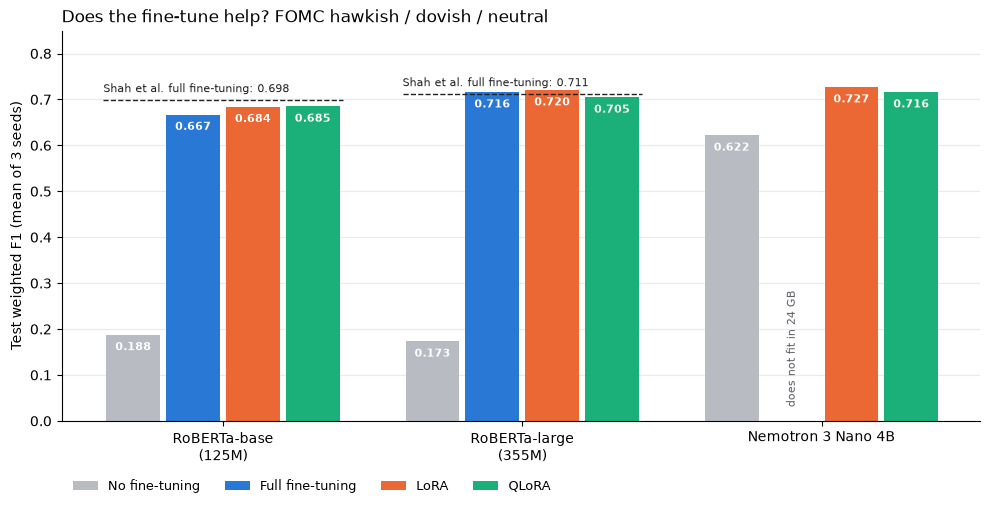

In [6]:
# Test weighted F1 by model and method, 3-seed means, from the live summary above.
MODELS = [("roberta-base", "RoBERTa-base\n(125M)"), ("roberta-large", "RoBERTa-large\n(355M)"), ("nemotron-nano-4b", "Nemotron 3 Nano 4B")]
METHODS = [("zeroshot", "No fine-tuning", "#b8bcc2"), ("full", "Full fine-tuning", "#2a78d6"),
           ("lora", "LoRA", "#eb6834"), ("qlora", "QLoRA", "#1baf7a")]
PAPER = {"roberta-base": 0.698, "roberta-large": 0.711}  # Shah et al. Table 5, full fine-tuning

ours = summary[summary["who"] == "ours"].set_index(["model", "method"])["weighted_f1"]
fig, ax = plt.subplots(figsize=(10, 5.2))
width = 0.2
for g, (model, _) in enumerate(MODELS):
    for k, (method, label, color) in enumerate(METHODS):
        x = g + (k - 1.5) * width
        f1 = ours.get((model, method))
        if f1 is None or pd.isna(f1):
            if (model, method) == ("nemotron-nano-4b", "full"):
                ax.text(x, 0.03, "does not fit in 24 GB", rotation=90, ha="center", va="bottom", fontsize=8, color="#5f6368")
            continue
        ax.bar(x, f1, width * 0.9, color=color, label=label if g == 0 else None)
        ax.text(x, f1 - 0.015, f"{f1:.3f}", ha="center", va="top", fontsize=8, color="white", fontweight="bold")
    if model in PAPER:
        ax.hlines(PAPER[model], g - 2 * width, g + 2 * width, colors="#202124", linestyles="--", linewidth=1)
        ax.text(g - 2 * width, PAPER[model] + 0.012, f"Shah et al. full fine-tuning: {PAPER[model]:.3f}", ha="left", va="bottom", fontsize=8, color="#202124")

ax.set_xticks(range(len(MODELS)), [name for _, name in MODELS])
ax.set_ylim(0, 0.85)
ax.set_ylabel("Test weighted F1 (mean of 3 seeds)")
ax.set_title("Does the fine-tune help? FOMC hawkish / dovish / neutral", loc="left", fontsize=12)
ax.grid(axis="y", color="#e8eaed", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.12), frameon=False, fontsize=9)
fig.tight_layout()
plt.show()


### Step 4: Classify new sentences

The next cell loads **Nemotron 3 Nano 4B with LoRA**, the best method in the results (0.727 mean over three seeds), using its best seed, and prints **model, method, seed, and F1** before classifying. If that checkpoint is not on this machine, it uses the RoBERTa-base model you trained in Step 2. Change `MODEL` / `METHOD` to try another row. LoRA / QLoRA adapters live in `final/`; `load_trained` attaches them to that run's base model.

Try your own sentences. Under the paper's definitions, sentences about strong growth (for example "economic activity was expanding at a moderate pace") often come out **hawkish**, because a strong economy is a reason to raise rates.


In [7]:
try:
    runs = load_runs()
except FileNotFoundError:  # no checkpoints on this machine
    runs = pd.DataFrame(columns=["who", "status", "model", "method", "checkpoint_dir"])
ours = runs[(runs["who"] == "ours") & (runs["status"] == "complete")]

# The talk's best method: Nemotron 3 Nano 4B + LoRA (0.727, 3-seed mean). Load its best seed.
MODEL, METHOD = "nemotron-nano-4b", "lora"
pick = ours[(ours["model"] == MODEL) & (ours["method"] == METHOD)]
pick = pick[pick["checkpoint_dir"].map(lambda p: (Path(str(p)) / "final").exists())]
if not pick.empty:
    best = pick.sort_values("weighted_f1", ascending=False).iloc[0]
else:
    # No Nemotron checkpoint on this machine: use the RoBERTa-base LoRA model from Step 2.
    print(f"No {MODEL} {METHOD} checkpoint here, so using the Step 2 RoBERTa-base LoRA model.")
    best = pd.Series({
        "model": demo["model"], "method": demo["method"], "seed": demo["seed"],
        "weighted_f1": demo["test"]["weighted_f1"], "device": demo["device"],
        "checkpoint_dir": demo["checkpoint_dir"],
    })
RUN_DIR = Path(best["checkpoint_dir"])
method = str(best["method"])
method_disp = {"full": "full FT", "lora": "LoRA", "qlora": "QLoRA"}.get(method, method)
display(
    pd.DataFrame(
        [
            {
                "model": best["model"],
                "method": method_disp,
                "seed": int(best["seed"]),
                "test weighted F1": round(float(best["weighted_f1"]), 4),
                "machine": machine_label(best.get("device"), "ours"),
                "checkpoint": RUN_DIR.name,
            }
        ]
    )
)
model, tokenizer = load_trained(RUN_DIR)

examples = [
    "The Committee judged that a further increase in the target range would be appropriate.",
    "The Committee decided to lower the target range for the federal funds rate.",
    "The Committee will continue to monitor the implications of incoming information for the economic outlook.",
]
# Argmax class only, softmax scores are not calibrated probabilities.
rows = predict_texts(model, tokenizer, examples)
pd.DataFrame(rows)[["text", "pred_name"]]

,model,method,seed,test weighted F1,machine,checkpoint
0,nemotron-nano-4b,LoRA,78516,0.7457,"RTX PRO 5000 Blackwell laptop, 24 GB, CUDA",nemotron-nano-4b__lora__lab-manual-split-combi...


Loading weights:   0%|          | 0/263 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/263 [00:00<01:08,  3.85it/s]

Loading weights:   6%|▌         | 15/263 [00:00<00:05, 48.73it/s]

Loading weights:  13%|█▎        | 35/263 [00:00<00:02, 90.30it/s]

...

Loading weights:  86%|████████▌ | 225/263 [00:01<00:00, 182.87it/s]

Loading weights:  93%|█████████▎| 245/263 [00:01<00:00, 163.78it/s]

Loading weights: 100%|██████████| 263/263 [00:02<00:00, 128.27it/s]

Loading weights: 100%|██████████| 263/263 [00:02<00:00, 128.92it/s]

,text,pred_name
0,The Committee judged that a further increase i...,hawkish
1,The Committee decided to lower the target rang...,dovish
2,The Committee will continue to monitor the imp...,neutral


### Step 5: Serve with vLLM

QLoRA is a **training-memory** tool, not an **inference** tool. To serve, fold the adapter into a bf16 base (`merge_adapter`) or attach it unmerged, and hand it to [vLLM](https://github.com/vllm-project/vllm): paged KV cache and continuous batching instead of a padded `model(**batch)` loop.

The classifier does not need a new head. Training already scores the LM-head logits of three label tokens at the last prompt token, so vLLM generates **one token, restricted to those three ids** (`allowed_token_ids`), greedy. Same prompt, same argmax, same prediction.

- **Merged** (`serve_vllm.py merge`): one checkpoint, no adapter at request time.
- **Unmerged** (`eval --lora`): base + adapter attached per request. One base can hot-swap many adapters (per customer, per task).
- **FP8 base** (`bench_inference.py ... --variant lora-fp8`): the LoRA adapter trained on the bf16 base works unchanged on NVIDIA's FP8 release of Nemotron 3 Nano 4B: **0.725** F1 (0.727 in training), **5.2 GB** of weights, about **100 sentences per second** on the laptop GPU.
- **Flyte**: `merge_adapter` is a `@gpu_env.task` in `workflow.py`; `vllm_app` in `flyte_env.py` is a `VLLMAppEnvironment` ([flyteplugins-vllm](https://www.union.ai/docs/v2/flyte/user-guide/apps/native-app-integrations/vllm-app/)) that serves that task's output behind an OpenAI-compatible API.

vLLM pins its own torch, so it lives in a second venv (`.venv-vllm`).


In [8]:
# vLLM serving. Needs an NVIDIA GPU and a finished Nemotron LoRA / QLoRA run. Commented: Run All is safe.
cmds = """
cd NLP/Fine_Tuning/fomc_peft
uv venv .venv-vllm --python 3.12 --managed-python   # managed build ships Python.h
VIRTUAL_ENV=.venv-vllm uv pip install vllm peft pandas openpyxl scikit-learn
VIRTUAL_ENV=.venv-vllm uv pip install flashinfer-jit-cache==<flashinfer version> --extra-index-url https://flashinfer.ai/whl/cu130
.venv/bin/python serve_vllm.py merge --method lora --seed 5768
.venv-vllm/bin/python serve_vllm.py eval --method lora --seed 5768          # merged
.venv-vllm/bin/python serve_vllm.py eval --method lora --seed 5768 --lora   # unmerged adapter
# The talk's FP8 numbers (0.725 F1, 5.2 GB, ~100 sentences/s), one line per seed:
.venv-vllm/bin/python bench_inference.py nemotron --method lora --variant lora-fp8 --seed 5768
# OpenAI-compatible server on this box:
# .venv-vllm/bin/vllm serve checkpoints/<run>/merged --served-model-name fomc-nemotron --max-model-len 512
# Same thing as a Flyte App (merge task output -> vLLM):
# flyte run workflow.py merge_adapter --method lora --seed 5768
# flyte deploy workflow.py vllm_app
""".strip()
print(cmds)
# !{cmds}


cd NLP/Fine_Tuning/fomc_peft
uv venv .venv-vllm --python 3.12 --managed-python   # managed build ships Python.h
VIRTUAL_ENV=.venv-vllm uv pip install vllm peft pandas openpyxl scikit-learn
VIRTUAL_ENV=.venv-vllm uv pip install flashinfer-jit-cache==<flashinfer version> --extra-index-url https://flashinfer.ai/whl/cu130
.venv/bin/python serve_vllm.py merge --method lora --seed 5768
.venv-vllm/bin/python serve_vllm.py eval --method lora --seed 5768          # merged
.venv-vllm/bin/python serve_vllm.py eval --method lora --seed 5768 --lora   # unmerged adapter
# The talk's FP8 numbers (0.725 F1, 5.2 GB, ~100 sentences/s), one line per seed:
.venv-vllm/bin/python bench_inference.py nemotron --method lora --variant lora-fp8 --seed 5768
# OpenAI-compatible server on this box:
# .venv-vllm/bin/vllm serve checkpoints/<run>/merged --served-model-name fomc-nemotron --max-model-len 512
# Same thing as a Flyte App (merge task output -> vLLM):
# flyte run workflow.py merge_adapter --method lora --se

In [9]:
# vLLM vs PyTorch on the same test split (written by serve_vllm.py eval).
import json

vllm_rows = [json.loads(p.read_text()) for p in sorted(cfg.CHECKPOINTS_DIR.glob("*/vllm_metrics*.json"))]
if vllm_rows:
    display(pd.DataFrame(vllm_rows)[
        ["model", "method", "seed", "serving", "pytorch_weighted_f1", "vllm_weighted_f1", "sentences_per_second"]
    ])
else:
    print("No vLLM results yet. Run the commands above.")

,model,method,seed,serving,pytorch_weighted_f1,vllm_weighted_f1,sentences_per_second
0,nemotron-nano-4b,qlora,5768,vllm-merged,0.700265,0.701632,80.7
1,nemotron-nano-4b,qlora,5768,vllm-lora,0.700265,0.699344,72.1


## Lessons: GPUs and memory

Measured on one RTX PRO 5000 Blackwell laptop GPU (24 GB), Combined-S, 3-seed means.

| Run | Trainable | Peak GPU memory | Test F1 |
|---|---|---|---|
| RoBERTa-large, full fine-tune | 100% | 11.8 GB | 0.716 |
| RoBERTa-large, LoRA | 2.2% | 9.9 GB | 0.720 |
| RoBERTa-large, QLoRA | 3.8% | 9.0 GB | 0.705 |
| Nemotron 3 Nano 4B, full fine-tune | 100% | ~38 GB (does not fit) | - |
| Nemotron 3 Nano 4B, LoRA | 1.7% | 9.0 GB | 0.727 |
| Nemotron 3 Nano 4B, QLoRA | 2.5% | 5.4 GB | 0.716 |

1. **PEFT shrinks gradients and optimizer state, not activations.** Training 2% of RoBERTa-large only saves 2 GB, because at batch 16 × 256 tokens the activations dominate. The savings grow with model size: a 4B model with QLoRA trains in less memory than a full RoBERTa-large fine-tune.
2. **Kernels can matter more than the method.** Without `causal-conv1d`, Nemotron's Mamba layers fall back to a pure-PyTorch path: ~17 GB of activations and ~30 min/epoch. With the fused kernels: 5.4 GB and ~6.5 min/epoch, same math. Check for "fast path not available" warnings before blaming the GPU.
3. **4-bit weights break code that touches weights directly.** The fused Mamba kernel reads `out_proj.weight`, so QLoRA keeps that layer in bf16. Checkpoints save only trainable parameters, because a quantized model's full `state_dict` does not load back.
4. **Measure after merging.** A QLoRA adapter was trained against an NF4 base; merged into bf16 it scored 0.699 in vLLM vs 0.700 in PyTorch (seed 5768). Close, but measure it; do not assume.
5. **Most fine-tuning runs peak early.** Nemotron's best validation F1 came at epoch 3, 3, and 7 across seeds; the rest is early stopping confirming it. Keep the best checkpoint, not the last.
6. **Know which memory is GPU memory.** "Shared GPU memory" on Windows is system RAM over PCIe, a slow spillover. Integrated graphics and the NPU cannot run CUDA training. One NVIDIA card is the whole budget.
7. **Serving is a different stack.** vLLM pins its own torch, so it gets its own environment. The LoRA adapter on NVIDIA's FP8 base served about 100 sentences/s at 0.725 F1 with 5.2 GB of weights; the merged bf16 model served about 81 sentences/s.


## CLI (same `workflow.py` everywhere)

Flyte 2 has no `@workflow`. You define a `TaskEnvironment`, then decorate functions with `@env.task` ([tasks](https://www.union.ai/docs/v2/flyte/user-guide/get-started/core-concepts/tasks/), [configuration](https://www.union.ai/docs/v2/union/user-guide/tasks/task-configuration/)). Those objects live in `flyte_env.py` / `workflow.py`. This notebook **imports them**: it does not define a second DAG.

- **`@cpu_env.task` `prepare_data`**: Combined-S xlsx (`cache="auto"`).
- **`@gpu_env.task` `train_one` / `grid`**: one model / method / seed, or many, on the GPU.
- **`@ui_env.task` `main`**: snapshot + comparison report. Drivers call children → **Sub actions**.
- **`release`**: shows held-out F1 vs the paper and waits for approval before `merge_adapter`.

All three command cells are commented so Run All does not start training.


In [10]:
# Flyte UI on a local devbox (needs Docker). Commented: Run All is safe.
# On WSL2, Kubernetes cannot see the GPU, so GPU tasks use a PodTemplate that mounts it.
cmds = """
cd NLP/Fine_Tuning/fomc_peft
source .venv/bin/activate
flyte start devbox
docker cp devbox/wsl-gpu-podtemplate.yaml flyte-devbox:/tmp/
docker exec flyte-devbox kubectl apply -f /tmp/wsl-gpu-podtemplate.yaml
mkdir -p .flyte && flyte create config --devbox -o .flyte/devbox.yaml
python -c "from report_helpers import refresh_report_snapshot; refresh_report_snapshot()"
FLYTE_WSL_GPU=1 flyte -c .flyte/devbox.yaml run --copy-style all workflow.py main
# http://localhost:30080/v2 -> the run -> Reports
""".strip()
print(cmds)
# !{cmds}


cd NLP/Fine_Tuning/fomc_peft
source .venv/bin/activate
flyte start devbox
docker cp devbox/wsl-gpu-podtemplate.yaml flyte-devbox:/tmp/
docker exec flyte-devbox kubectl apply -f /tmp/wsl-gpu-podtemplate.yaml
mkdir -p .flyte && flyte create config --devbox -o .flyte/devbox.yaml
python -c "from report_helpers import refresh_report_snapshot; refresh_report_snapshot()"
FLYTE_WSL_GPU=1 flyte -c .flyte/devbox.yaml run --copy-style all workflow.py main
# http://localhost:30080/v2 -> the run -> Reports


In [11]:
# In this process, no Docker (flyte run --local). Commented: Run All is safe.
cmds = """
cd NLP/Fine_Tuning/fomc_peft
source .venv/bin/activate
flyte run --local workflow.py train_one --model_key nemotron-nano-4b --method qlora --seed 5768
flyte run --local workflow.py grid --seeds '[5768]' --include_qlora true --include_nemotron
flyte run --local workflow.py release    # y: merge seed 5768 for vLLM, n: stop
""".strip()
print(cmds)
# !{cmds}


cd NLP/Fine_Tuning/fomc_peft
source .venv/bin/activate
flyte run --local workflow.py train_one --model_key nemotron-nano-4b --method qlora --seed 5768
flyte run --local workflow.py grid --seeds '[5768]' --include_qlora true --include_nemotron
flyte run --local workflow.py release    # y: merge seed 5768 for vLLM, n: stop


In [12]:
# Without Flyte: train directly on this GPU. Commented: Run All is safe.
cmds = """
cd NLP/Fine_Tuning/fomc_peft
bash run_fomc.sh nemotron-lora   # one-time: mamba-ssm + fused kernels, then one Nemotron LoRA seed
python train_run.py --model nemotron-nano-4b --method qlora --seed 5768
python train_run.py --model nemotron-nano-4b --method zeroshot --seed 5768
python run_grid.py --models roberta-base,roberta-large --methods full,lora,qlora \\
    --seeds 5768,78516,944601 --include-qlora --include-large-full
""".strip()
print(cmds)
# !{cmds}


cd NLP/Fine_Tuning/fomc_peft
bash run_fomc.sh nemotron-lora   # one-time: mamba-ssm + fused kernels, then one Nemotron LoRA seed
python train_run.py --model nemotron-nano-4b --method qlora --seed 5768
python train_run.py --model nemotron-nano-4b --method zeroshot --seed 5768
python run_grid.py --models roberta-base,roberta-large --methods full,lora,qlora \
    --seeds 5768,78516,944601 --include-qlora --include-large-full
